# Midterm 2: Contact map and IUPred-like energy profiles for `5OUG_B`

This notebook solves the assigned tasks for protein chain **5oug_B**:

1. download the assigned PDB structure and keep only standard residues of chain B;
2. calculate and plot the contact map using `NeighborSearch.search_all(3.5, level="R")` and sequence separation ≥ 2;
3. calculate exact contact energy from the **M matrix**;
4. calculate estimated IUPred-like energy from the **P matrix**;
5. report disorder content as the fraction and count of residues with energy ≥ 0.

In [1]:
# If running in Google Colab, mount Google Drive.
# If not using Colab, this cell can be skipped.
try:
    from google.colab import drive
    drive.mount('/content/drive/')
except Exception as e:
    print("Not running in Colab or Drive already unavailable:", e)

Mounted at /content/drive/


In [2]:
# Set paths
import os

# Change this path if your data folder is elsewhere.
path = 'drive/MyDrive/Colab Notebooks/Structural Biology/data'

pdb_dir = os.path.join(path, 'pdb')
fig_dir = os.path.join(path, 'figures')

os.makedirs(pdb_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)

print('PDB directory:', pdb_dir)
print('Figures directory:', fig_dir)

PDB directory: drive/MyDrive/Colab Notebooks/Structural Biology/data/pdb
Figures directory: drive/MyDrive/Colab Notebooks/Structural Biology/data/figures


In [3]:
# Install dependencies if needed
!pip -q install biopython scipy matplotlib pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 34.5 MB/s eta 0:00:00


In [4]:
import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import colors

from Bio.PDB import PDBList, PDBParser, NeighborSearch
from Bio.SeqUtils import seq1

In [5]:
# Load IUPred matrices from iupred_data.py
# The file must define: aa_list, p_matrix, m_matrix

iupred_data_path = os.path.join(path, 'iupred_data.py')

with open(iupred_data_path, 'r') as f:
    exec(f.read())

p_matrix = np.array(p_matrix, dtype=float)
m_matrix = np.array(m_matrix, dtype=float)

print('aa_list:', aa_list)
print('P matrix shape:', p_matrix.shape)
print('M matrix shape:', m_matrix.shape)

aa_list: ['A', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'P', 'Q', 'R', 'S', 'T', 'V', 'W', 'Y']
P matrix shape: (20, 20)
M matrix shape: (20, 20)


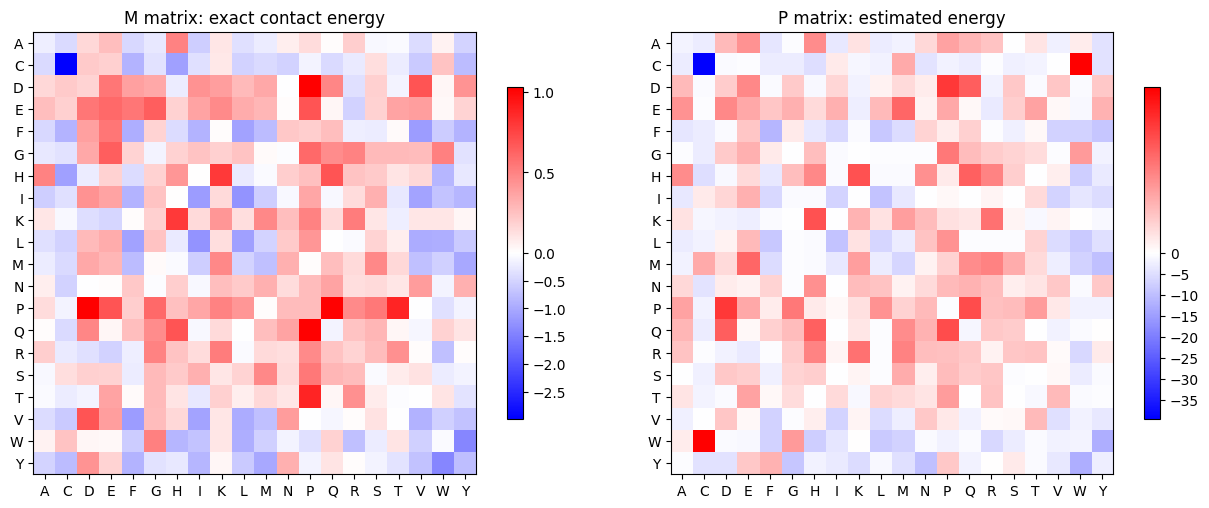

In [6]:
# Plot M and P matrices to inspect the energy scales
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, matrix, title in zip(axes, [m_matrix, p_matrix], ['M matrix: exact contact energy', 'P matrix: estimated energy']):
    divnorm = colors.TwoSlopeNorm(vmin=np.nanmin(matrix), vcenter=0, vmax=np.nanmax(matrix))
    im = ax.imshow(matrix, interpolation='none', cmap='bwr', norm=divnorm)
    ax.set_title(title)
    ax.set_xticks(range(len(aa_list)))
    ax.set_xticklabels(aa_list)
    ax.set_yticks(range(len(aa_list)))
    ax.set_yticklabels(aa_list)
    fig.colorbar(im, ax=ax, shrink=0.75)

plt.tight_layout()
plt.savefig(os.path.join(fig_dir, 'iupred_M_P_matrices.png'), dpi=300, bbox_inches='tight')
plt.show()

## 1. Download PDB and select chain B

Only standard residues are kept: `residue.id[0] == " "`. Hetero groups, water molecules, ligands and ions are excluded.

In [7]:
# Input
pdb_id = '5oug'
chain_id = 'B'

# Download PDB file
pdbl = PDBList()
pdb_file = pdbl.retrieve_pdb_file(pdb_id, pdir=pdb_dir, file_format='pdb')

# Biopython usually saves PDB files as pdbXXXX.ent
pdb_file = os.path.join(pdb_dir, f'pdb{pdb_id}.ent')
print('PDB file:', pdb_file)

# Parse structure
structure = PDBParser(QUIET=True).get_structure(pdb_id, pdb_file)
model = structure[0]
chain = model[chain_id]

# Keep only standard residues from the selected chain
residues = [res for res in chain if res.id[0] == ' ']
residue_ids = [res.id[1] for res in residues]
seq = ''.join(seq1(res.get_resname()) for res in residues)

print(f'Structure: {pdb_id.upper()}_{chain_id}')
print('Number of standard residues:', len(residues))
print('First residues:', residue_ids[:10])
print('Sequence length:', len(seq))
print(seq)

Structure exists: 'drive/MyDrive/Colab Notebooks/Structural Biology/data/pdb/pdb5oug.ent' 
PDB file: drive/MyDrive/Colab Notebooks/Structural Biology/data/pdb/pdb5oug.ent
Structure: 5OUG_B
Number of standard residues: 205
First residues: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Sequence length: 205
GEFQRKLYKELVKNYNPDVIPTQRDRPVTVYFSLSLLQIMDVDEKNQVVDVVIWLQMSWTDHYLQWNVSEYPGVKQVSVPISSLWKPDILLYNAIERPEVLTPQLALVNSSGHVQYLPSIRQRFSCDVSGVDTESGATCKLKFGSWTHHSRELDLQMQEADISGYIPYSRFELVGVTQKRSERFYECCKEPYPDVTFTVTFRKKG


## Helper functions

The moving average is centered and uses a window of 21 residues, meaning ±10 residues around the current position. At sequence ends, the available part of the window is used.

In [8]:
def moving_average_centered(values, half_window=10):
    """
    Centered moving average with window size 2*half_window + 1.
    For terminal residues, use the available part of the window.
    """
    values = np.asarray(values, dtype=float)
    smoothed = np.zeros_like(values, dtype=float)

    for i in range(len(values)):
        start = max(0, i - half_window)
        end = min(len(values), i + half_window + 1)
        smoothed[i] = np.nanmean(values[start:end])

    return smoothed


def aa_index(aa):
    """Return index of one-letter amino acid code in aa_list."""
    return aa_list.index(aa)

## 2. Contact map using `NeighborSearch.search_all(3.5, level="R")`

A contact is counted if:

- two residues have at least one atom pair within **3.5 Å**;
- their sequence separation is **≥ 2**, so immediate backbone neighbours are excluded.

In [9]:
def calculate_contact_map_neighborsearch(residues, radius=3.5, min_seq_sep=2):
    """
    Calculate a binary residue contact map using Bio.PDB NeighborSearch.

    Parameters
    ----------
    residues : list of Bio.PDB.Residue
        Standard residues from one chain.
    radius : float
        Spatial distance cutoff in Angstrom.
    min_seq_sep : int
        Minimum sequence separation |i-j|.

    Returns
    -------
    contact_map : np.ndarray, shape (L, L)
        Binary symmetric matrix. 1 means contact, 0 means no contact.
    contact_pairs : list of tuple
        List of unique residue index pairs (i, j), i < j.
    """
    atoms = [atom for residue in residues for atom in residue.get_atoms()]
    ns = NeighborSearch(atoms)

    residue_to_index = {id(residue): i for i, residue in enumerate(residues)}
    L = len(residues)
    contact_map = np.zeros((L, L), dtype=int)
    contact_pairs = []

    for residue1, residue2 in ns.search_all(radius, level='R'):
        if id(residue1) not in residue_to_index or id(residue2) not in residue_to_index:
            continue

        i = residue_to_index[id(residue1)]
        j = residue_to_index[id(residue2)]

        if i == j:
            continue

        if abs(i - j) >= min_seq_sep:
            a, b = sorted((i, j))
            if contact_map[a, b] == 0:
                contact_pairs.append((a, b))
            contact_map[a, b] = 1
            contact_map[b, a] = 1

    return contact_map, contact_pairs


contact_map, contact_pairs = calculate_contact_map_neighborsearch(
    residues,
    radius=3.5,
    min_seq_sep=2
)

print('Number of unique residue-residue contacts:', len(contact_pairs))
print('Contact map shape:', contact_map.shape)

Number of unique residue-residue contacts: 303
Contact map shape: (205, 205)


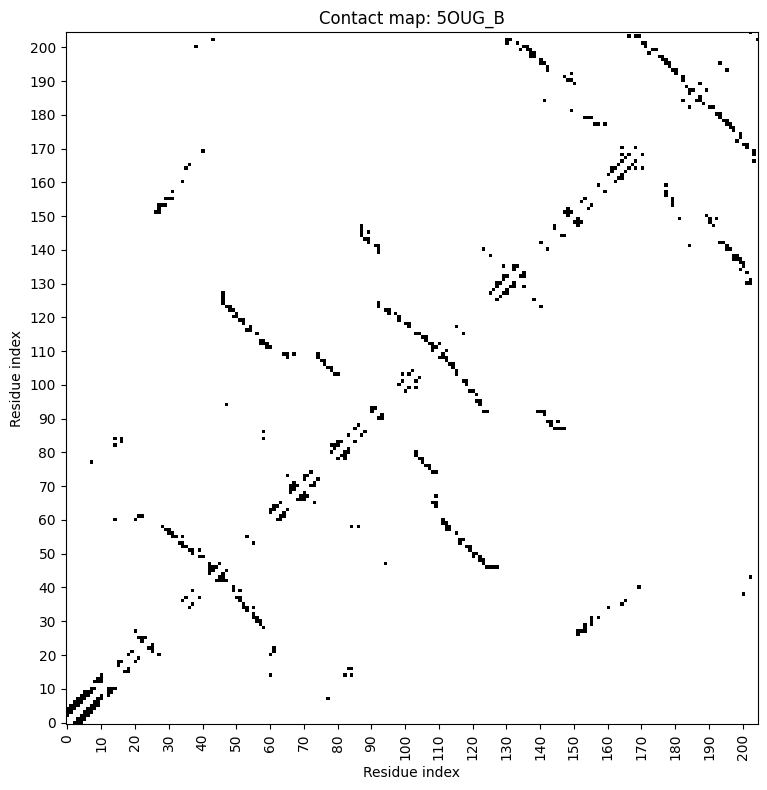

In [13]:
# Plot contact map
fig, ax = plt.subplots(figsize=(8, 8))
im = ax.imshow(contact_map, origin='lower', cmap='Greys')

step = max(1, len(residue_ids) // 20)
ax.set_xticks(range(0, len(residue_ids), step))
ax.set_yticks(range(0, len(residue_ids), step))
ax.set_xticklabels(residue_ids[::step], rotation=90)
ax.set_yticklabels(residue_ids[::step])

ax.set_xlabel('Residue index')
ax.set_ylabel('Residue index')
ax.set_title(f'Contact map: {pdb_id.upper()}_{chain_id}')

plt.tight_layout()
plt.savefig(os.path.join(fig_dir, f'contact_map_{pdb_id}_{chain_id}.png'), dpi=300, bbox_inches='tight')
plt.show()

## 3. Exact contact energy using the M matrix

For each residue *i*, we collect all residues *j* in contact with it and average the corresponding pairwise contact energies from the M matrix:

\[
E_i^{exact} =
rac{1}{N_i}\sum_{j \in contacts(i)} M_{aa_i, aa_j}
\]

If a residue has no contacts, its energy is set to 0, meaning no stabilizing contacts were observed in this contact-map definition.

In [26]:
def iupred(seq, sequence_separation=2, window_size=100, window_size_smooth=10):
    '''
    Calculate per residue IUPred energy considering windows_size neighbouring
    residues and applying a smoothing with a sliding window window_size_smooth
    long

    :param seq: a string of aminoacids
    :param sequence_separation: neighbours min distance
    :param window_size: neighbours max distance
    :param window_size_smooth: sliding window size
    :return: row prediction, smoothed prediction
    '''

    pred = []  # Calculated energy per sequence position
    pred_smooth = []

    indices = [aa_list.index(aa) for aa in list(seq)]  # Transform sequence into indexes as in the P matrix
    # print(indices)
    # return None, None

    for i, aa_index in enumerate(indices): #i=индекс в последовательности, aa_index=номер АК из p-matrix

        # Get the slice i-100/i+100 excluding adjacent positions (+/-1) исключая исслед позицию i и 2 самые ближние к ней
        start_before = max(0, i - window_size)
        end_before = max(0, i - sequence_separation)

        start_after = min(len(indices), i + sequence_separation)
        end_after = min(len(indices), i + window_size + 1)
        indices_local = indices[start_before: end_before] + indices[start_after: end_after]
        # print(i, aa_index, aa_list[aa_index], len(indices), len(indices_local), start_before, end_before, start_after, end_after)

        # Count the different amino acids in the window
        '''
        Что делает: создаёт вектор длиной 20,
        где каждая позиция это количество одной аминокислоты в локальном окне.
        Пример: если в окне много A, P, S,
        то соответствующие позиции в row будут большими.
        '''
        row = np.full((20,), 0)
        for index in indices_local:
            row[index] += 1
        # print(row)

        # calculate AA frequency = превращает количество аминокислот в частоты
        row = row / len(indices_local)
        # print(row)

        # calculate energy = берёт строку p_matrix,
        # соответствующую текущей аминокислоте,
        # и умножает её на частоты аминокислот в окружении
        row = row * p_matrix[aa_index, ]
        # print(row)

        aa_energy = np.sum(row)
        # print(i, seq[i], aa_energy)
        '''
        energy(current residue) =
        frequency(A) * P[current, A] +
        frequency(C) * P[current, C] +
        frequency(D) * P[current, D] +
        ...
        frequency(Y) * P[current, Y]
        '''

        pred.append(aa_energy)

    # Smooth the prediction (moving average)
    '''
    Что делает: берёт маленькое окно вокруг каждой позиции и считает среднее.
    Зачем: чтобы убрать шум.
    Если одна аминокислота дала резкий пик, это может быть случайность.
    Если высокий или низкий сигнал держится на длинном участке,
    это уже биологически интереснее.
    '''
    for i in range(len(pred)):
        frag = pred[max(0, i - window_size_smooth): min(i + window_size_smooth + 1, len(pred))]
        pred_smooth.append(sum(frag) / len(frag))

    return pred, pred_smooth
    #pred: сырой профиль
    #pred_smooth: сглаженный профиль

Structure exists: 'drive/MyDrive/Colab Notebooks/Structural Biology/data/pdb/pdb5oug.ent' 
5oug B GEFQRKLYKELVKNYNPDVIPTQRDRPVTVYFSLSLLQIMDVDEKNQVVDVVIWLQMSWTDHYLQWNVSEYPGVKQVSVPISSLWKPDILLYNAIERPEVLTPQLALVNSSGHVQYLPSIRQRFSCDVSGVDTESGATCKLKFGSWTHHSRELDLQMQEADISGYIPYSRFELVGVTQKRSERFYECCKEPYPDVTFTVTFRKKG


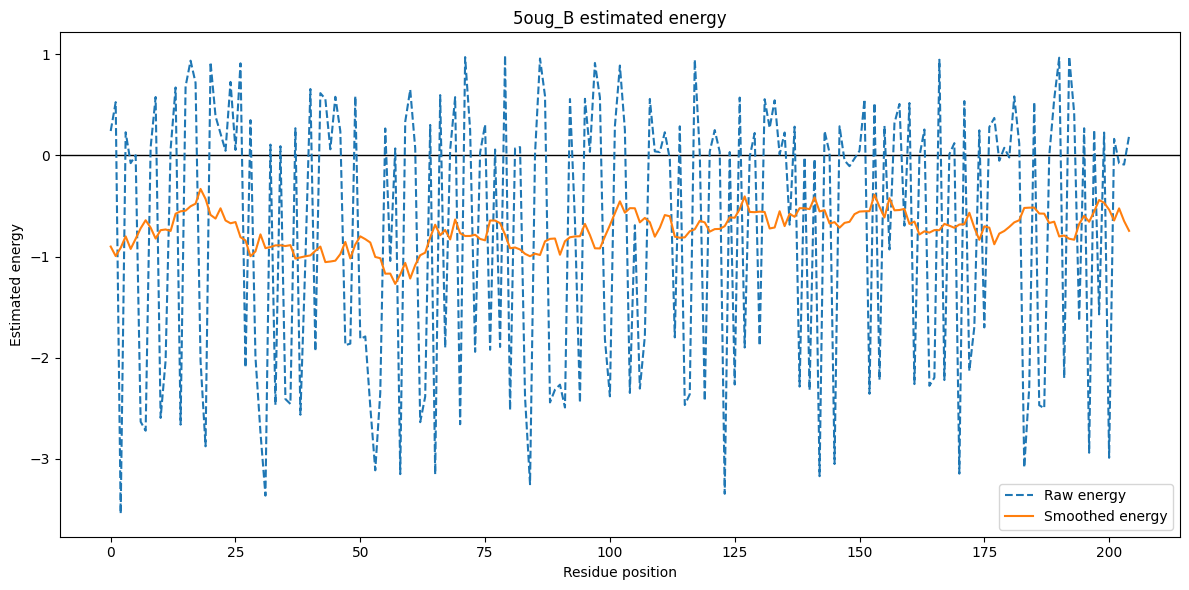

In [31]:
# IUPred prediction
pdb_ids = [('5oug', 'B')]

pdbl = PDBList()

for pdb_id, chain_id in pdb_ids:

    pdbl.retrieve_pdb_file(pdb_id, pdir=path + "/pdb", file_format='pdb')
    structure = PDBParser(QUIET=True).get_structure(
        pdb_id,
        path + "/pdb/pdb{}.ent".format(pdb_id)
    )

    # Select standard residues from the required chain
    residues = [
        residue for residue in structure[0][chain_id]
        if residue.id[0] == " "
    ]

    # Convert 3-letter residue names to 1-letter sequence
    seq = "".join([seq1(residue.get_resname()) for residue in residues])

    print(pdb_id, chain_id, seq)

    # Generate the prediction
    pred, pred_smooth = iupred(seq)

    fig, ax = plt.subplots(figsize=(12, 6))
    ax.set_title("{}_{}".format(pdb_id, chain_id) + ' estimated energy')
    ax.axhline(0, color='black', linewidth=1)
    ax.plot(np.arange(len(seq)), pred, ls='--', label='Raw energy')
    ax.plot(np.arange(len(seq)), pred_smooth, ls='-', label='Smoothed energy')

    ax.set_xlabel("Residue position")
    ax.set_ylabel("Estimated energy")
    ax.legend()

    plt.tight_layout()
    plt.savefig(
        path + '/figures/iupred_{}_{}.png'.format(pdb_id, chain_id),
        dpi=300,
        bbox_inches='tight'
    )
    plt.show()

Structure exists: 'drive/MyDrive/Colab Notebooks/Structural Biology/data/pdb/pdb5oug.ent' 
5oug B GEFQRKLYKELVKNYNPDVIPTQRDRPVTVYFSLSLLQIMDVDEKNQVVDVVIWLQMSWTDHYLQWNVSEYPGVKQVSVPISSLWKPDILLYNAIERPEVLTPQLALVNSSGHVQYLPSIRQRFSCDVSGVDTESGATCKLKFGSWTHHSRELDLQMQEADISGYIPYSRFELVGVTQKRSERFYECCKEPYPDVTFTVTFRKKG
Number of residues: 205
Number of unique residue-residue contacts: 303
Contact map shape: (205, 205)


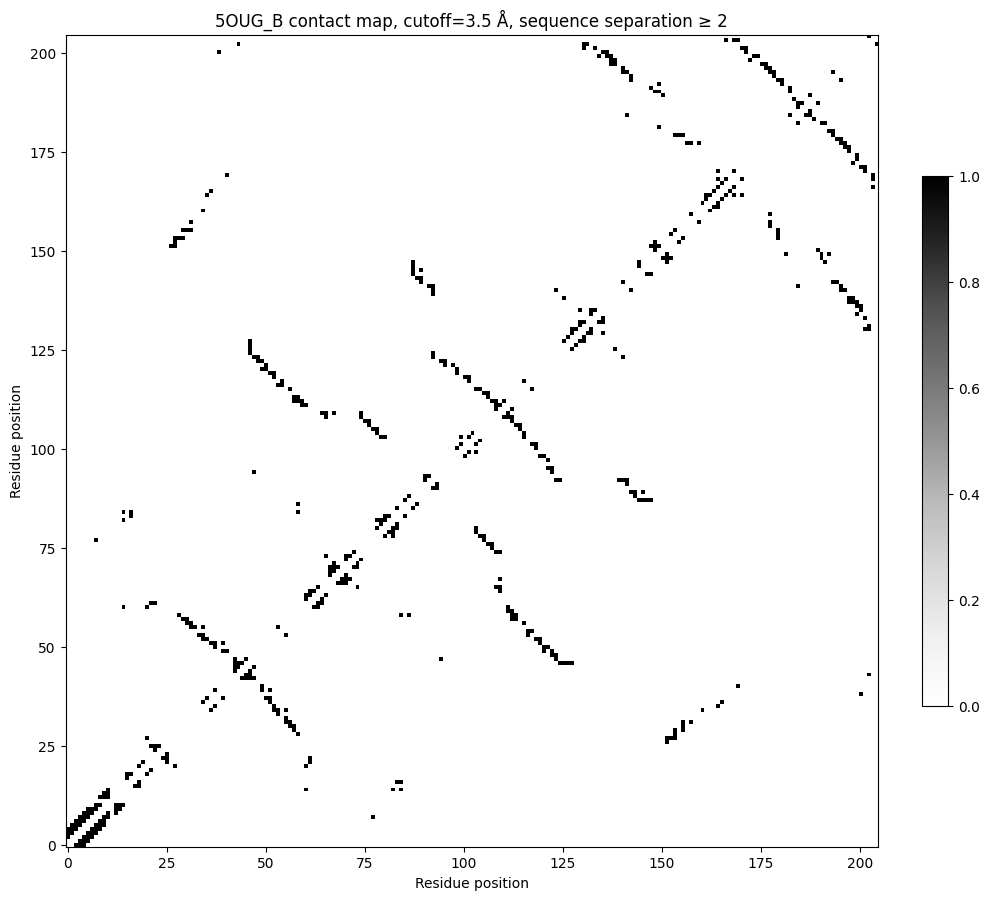

Residues with at least one contact: 201
Residues without contacts: 4


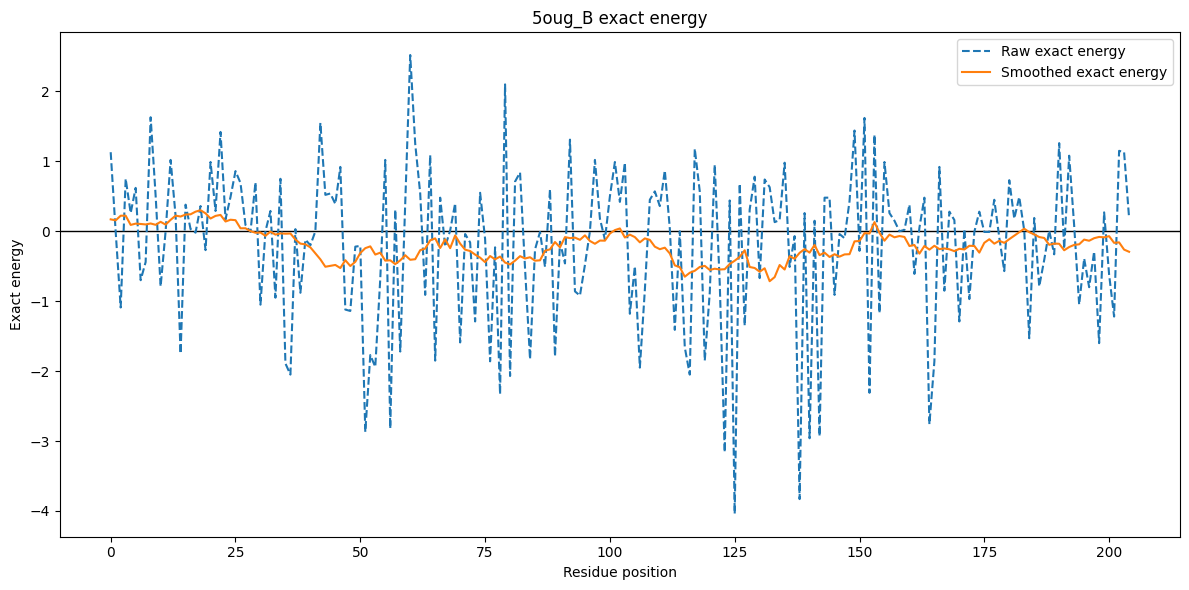

In [32]:
import numpy as np
import matplotlib.pyplot as plt
from Bio.PDB import PDBList, PDBParser, NeighborSearch
from Bio.SeqUtils import seq1

# =========================
# Input
# =========================
pdb_id = "5oug"
chain_id = "B"

radius = 3.5
min_seq_sep = 2
smooth_window = 10  # ±10 residues, total window = 21

# =========================
# Load structure
# =========================
pdbl = PDBList()
pdbl.retrieve_pdb_file(pdb_id, pdir=path + "/pdb", file_format="pdb")

structure = PDBParser(QUIET=True).get_structure(
    pdb_id,
    path + "/pdb/pdb{}.ent".format(pdb_id)
)

# Select standard residues only
residues = [
    residue for residue in structure[0][chain_id]
    if residue.id[0] == " "
]

seq = "".join([seq1(residue.get_resname()) for residue in residues])

print(pdb_id, chain_id, seq)
print("Number of residues:", len(residues))

# =========================
# Q5: Contact map with NeighborSearch
# =========================
def calculate_contact_map_neighborsearch(residues, radius=3.5, min_seq_sep=2):
    """
    Calculate a binary residue contact map using Bio.PDB NeighborSearch.
    Contacts are residue-residue pairs returned by search_all(radius, level='R').
    Only contacts with sequence separation >= min_seq_sep are kept.
    """
    atoms = [atom for residue in residues for atom in residue.get_atoms()]
    ns = NeighborSearch(atoms)

    residue_to_index = {id(residue): i for i, residue in enumerate(residues)}

    L = len(residues)
    contact_map = np.zeros((L, L), dtype=int)
    contact_pairs = []

    for residue1, residue2 in ns.search_all(radius, level="R"):
        if id(residue1) not in residue_to_index:
            continue
        if id(residue2) not in residue_to_index:
            continue

        i = residue_to_index[id(residue1)]
        j = residue_to_index[id(residue2)]

        if i == j:
            continue

        if abs(i - j) >= min_seq_sep:
            a, b = sorted((i, j))

            if contact_map[a, b] == 0:
                contact_pairs.append((a, b))

            contact_map[a, b] = 1
            contact_map[b, a] = 1

    return contact_map, contact_pairs


contact_map, contact_pairs = calculate_contact_map_neighborsearch(
    residues,
    radius=radius,
    min_seq_sep=min_seq_sep
)

print("Number of unique residue-residue contacts:", len(contact_pairs))
print("Contact map shape:", contact_map.shape)

# Plot contact map
fig, ax = plt.subplots(figsize=(10, 10))

im = ax.imshow(contact_map, cmap="Greys", origin="lower")

ax.set_title(
    "{}_{} contact map, cutoff={} Å, sequence separation ≥ {}".format(
        pdb_id.upper(), chain_id, radius, min_seq_sep
    )
)
ax.set_xlabel("Residue position")
ax.set_ylabel("Residue position")

fig.colorbar(im, fraction=0.03, pad=0.05)

plt.tight_layout()
plt.savefig(
    path + "/figures/contact_map_{}_{}.png".format(pdb_id, chain_id),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# =========================
# Q6: Exact conformational energy from the same contacts
# =========================
def moving_average(values, window_size=10):
    """
    Moving average over ±window_size residues.
    For window_size=10, total window is 21 residues.
    """
    values_smooth = []

    for i in range(len(values)):
        start = max(0, i - window_size)
        end = min(len(values), i + window_size + 1)

        frag = values[start:end]
        values_smooth.append(np.mean(frag))

    return np.array(values_smooth)


def calculate_exact_energy_from_contacts(seq, contact_pairs, m_matrix):
    """
    Calculate exact residue-wise conformational energy using M matrix
    and the same contact pairs from Q5.

    For each contact (i, j):
    energy M[aa_i, aa_j] is added to residue i and residue j.
    """
    aa_indices = [aa_list.index(aa) for aa in seq]

    exact_energy = np.zeros(len(seq), dtype=float)
    contact_counts = np.zeros(len(seq), dtype=int)

    for i, j in contact_pairs:
        aa_i = aa_indices[i]
        aa_j = aa_indices[j]

        contact_energy = m_matrix[aa_i, aa_j]

        exact_energy[i] += contact_energy
        exact_energy[j] += contact_energy

        contact_counts[i] += 1
        contact_counts[j] += 1

    return exact_energy, contact_counts


exact_energy_raw, contact_counts = calculate_exact_energy_from_contacts(
    seq,
    contact_pairs,
    m_matrix
)

exact_energy_smooth = moving_average(
    exact_energy_raw,
    window_size=smooth_window
)

print("Residues with at least one contact:", np.sum(contact_counts > 0))
print("Residues without contacts:", np.sum(contact_counts == 0))

# Plot exact energy
fig, ax = plt.subplots(figsize=(12, 6))

ax.set_title("{}_{} exact energy".format(pdb_id.upper().lower(), chain_id))
ax.axhline(0, color="black", linewidth=1)

ax.plot(
    np.arange(len(seq)),
    exact_energy_raw,
    ls="--",
    label="Raw exact energy"
)

ax.plot(
    np.arange(len(seq)),
    exact_energy_smooth,
    ls="-",
    label="Smoothed exact energy"
)

ax.set_xlabel("Residue position")
ax.set_ylabel("Exact energy")
ax.legend()

plt.tight_layout()
plt.savefig(
    path + "/figures/exact_energy_M_{}_{}.png".format(pdb_id, chain_id),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## 5. Disorder content

Disorder content is calculated as:

\[
	ext{disorder content} =
rac{\#\{i : E_i \geq 0\}}{L}
\]

The assignment asks for two calculations, so the table reports disorder content for the **exact M-based energy** and the **estimated P-based energy**. Both raw and smoothed profiles are shown for transparency; the smoothed values are usually easier to interpret biologically.

In [36]:
# Disorder content from plotted smoothed curves

exact_positive_count = np.sum(np.array(exact_energy_smooth) >= 0)
exact_fraction = exact_positive_count / len(exact_energy_smooth)

estimated_positive_count = np.sum(np.array(estimated_energy_smooth) >= 0)
estimated_fraction = estimated_positive_count / len(estimated_energy_smooth)

print("Exact energy disorder content")
print("Positive-energy residues:", exact_positive_count)
print("Fraction:", exact_fraction)

print("\nEstimated energy disorder content")
print("Positive-energy residues:", estimated_positive_count)
print("Fraction:", estimated_fraction)

Exact energy disorder content
Positive-energy residues: 33
Fraction: 0.16097560975609757

Estimated energy disorder content
Positive-energy residues: 0
Fraction: 0.0


In [48]:
# Disorder content from raw energy values

exact_positive_count = np.sum(np.array(exact_energy_raw) >= 0)
exact_fraction = exact_positive_count / len(exact_energy_raw)

estimated_positive_count = np.sum(np.array(estimated_energy_raw) >= 0)
estimated_fraction = estimated_positive_count / len(estimated_energy_raw)

print("Exact energy disorder content")
print("Positive-energy residues:", exact_positive_count)
print("Fraction:", round(exact_fraction, 4))

print("\nEstimated energy disorder content")
print("Positive-energy residues:", estimated_positive_count)
print("Fraction:", round(estimated_fraction, 4))

print("\nArrays are identical:", np.array_equal(np.array(exact_energy_raw), np.array(pred)))
print("Different classified residues:", np.sum(exact_mask != estimated_mask))

Exact energy disorder content
Positive-energy residues: 107
Fraction: 0.522

Estimated energy disorder content
Positive-energy residues: 107
Fraction: 0.522

Arrays are identical: False
Different classified residues: 48


In [45]:
exact_mask = np.array(exact_energy_raw) >= 0
estimated_mask = np.array(pred) >= 0

print("Exact count:", np.sum(exact_mask))
print("Estimated count:", np.sum(estimated_mask))

print("Same positive/negative pattern:", np.array_equal(exact_mask, estimated_mask))
print("Different classified residues:", np.sum(exact_mask != estimated_mask))

print("Exact range:", np.min(exact_energy_raw), np.max(exact_energy_raw))
print("Estimated range:", np.min(pred), np.max(pred))

Exact count: 107
Estimated count: 107
Same positive/negative pattern: False
Different classified residues: 48
Exact range: -4.04 2.52
Estimated range: -3.5458585858585856 0.9919886363636363


In [43]:
print(exact_energy_raw == pred)

True


## Short interpretation template

Use this text in the report and replace the table values after running the notebook:

> For chain 5OUG_B, I first selected only standard residues from chain B and calculated a residue-residue contact map using `NeighborSearch.search_all(3.5, level="R")`. Contacts between residues with sequence separation < 2 were excluded. Exact contact energy was calculated from observed contacts using the M matrix, while estimated energy was calculated from local sequence composition using the P matrix and neighbours from i±2 to i±100. The raw profiles were smoothed with a centered moving average of 21 residues. Disorder content was reported as the number and fraction of residues with energy ≥ 0.